Import our libraries and data

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("NY_Wage_Stats.csv")

Now let's clean our data

In [3]:
df.columns = df.columns.str.strip()
df = df[df["Occupational Title"] != "Total, All Occupations"]
df = df[df["Area"] != 36]
df = df.reset_index(drop=True)
df = df.dropna(subset=["Mean Wage","Experienced Wage"])
df

,Area Type,Area,Area Name,Standard Occupational Code,Occupational Title,Employment,Mean Wage,Median Wage,Entry Wage,Experienced Wage
0,10,1,Capital Region,11-0000,Management Occupations,33180.0,140435,124254.0,72779,174264.0
1,10,1,Capital Region,11-1011,Chief Executives,680.0,196059,176046.0,118185,234996.0
2,10,1,Capital Region,11-1021,General and Operations Managers,11200.0,135584,106886.0,62686,172033.0
3,10,1,Capital Region,11-1031,Legislators,410.0,136546,144622.0,78796,165419.0
4,10,1,Capital Region,11-2011,Advertising and Promotions Managers,70.0,178260,134711.0,74496,230142.0
...,...,...,...,...,...,...,...,...,...,...
6240,10,10,Western New York,53-7064,"Packers and Packagers, Hand",1360.0,37669,36423.0,32240,40388.0
6241,10,10,Western New York,53-7065,Stockers and Order Fillers,11540.0,40552,38276.0,33614,44023.0
6242,10,10,Western New York,53-7073,Wellhead Pumpers,NaN,46873,45740.0,35580,52520.0
6243,10,10,Western New York,53-7081,Refuse and Recyclable Material Collectors,340.0,47399,48664.0,36261,52968.0


Now let's select our features (x = mean wage) and our target (y = experienced wage)

In [4]:
X = df["Mean Wage"].values
Y = df["Experienced Wage"].values

Shuffle indices and split our data for train / test

In [5]:
np.random.seed(42)
indices = np.random.permutation(len(df))

split = int(0.8 * len(df))
train_idx = indices[:split]
test_idx = indices[split:]

X_train, Y_train = X[train_idx], Y[train_idx]
X_test, Y_test = X[test_idx], Y[test_idx]

Now let's create 3 functions, one will be to fit our regression based off of our train set, the next will be used to predict based off of our X_test, the final will compute the R^2 value based off of our Y_true (y_test in this case) and our y_pred (which we will get from the applied function)

In [6]:
def linear_regression_fit(X, Y):
    X_mean = np.mean(X)
    Y_mean = np.mean(Y)

    beta1 = np.sum((X - X_mean) * (Y - Y_mean)) / np.sum((X - X_mean)**2)
    beta0 = Y_mean - beta1 * X_mean

    return beta0, beta1


def linear_regression_predict(X, beta0, beta1):
    return beta0 + beta1*X

def r_squared(Y_true, Y_pred):
    ss_res = np.sum((Y_true - Y_pred)**2)
    ss_tot = np.sum((Y_true - np.mean(Y_true))**2)
    return 1 - (ss_res / ss_tot)

Now let's fit the model

In [7]:
beta0, beta1 = linear_regression_fit(X_train, Y_train)

print("Intercept: ", beta0)
print("Slope: ", beta1)

Intercept:  -8744.156546824408
Slope:  1.2745210882332414


Predict on the test set and get an R^2 Value

In [9]:
Y_Pred = linear_regression_predict(X_test, beta0, beta1)

print("R^2: ", r_squared(Y_test, Y_Pred))

import statsmodels.api as sm
import numpy as np

X_sm1 = sm.add_constant(X)
model1 = sm.OLS(Y, X_sm1).fit()

print(model1.summary())

R^2:  0.9920513606317108
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.992
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                 7.624e+05
Date:                Mon, 24 Nov 2025   Prob (F-statistic):               0.00
Time:                        11:51:53   Log-Likelihood:                -61077.
No. Observations:                6182   AIC:                         1.222e+05
Df Residuals:                    6180   BIC:                         1.222e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -8714.4045    13

This R^2 value is incredibly high, which indicates 99% of the variance of experienced wage can be explained by mean wage,

Now let's make some graphs, first a basic visualization of this linear regression to test for linearity

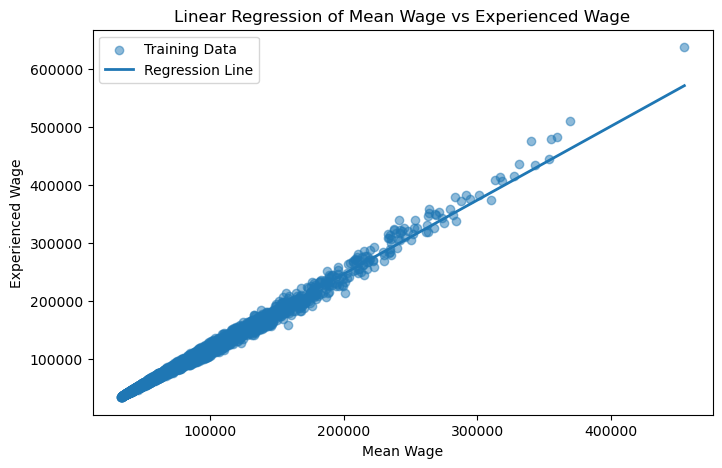

In [10]:
import matplotlib.pyplot as plt
import numpy as np

X_line = np.linspace(min(X_train), max(X_train), 100)
Y_line = beta0 + beta1 * X_line

plt.figure(figsize=(8,5))
plt.scatter(X_train, Y_train, alpha=0.5, label="Training Data")
plt.plot(X_line, Y_line, label="Regression Line", linewidth=2)
plt.xlabel("Mean Wage")
plt.ylabel("Experienced Wage")
plt.title("Linear Regression of Mean Wage vs Experienced Wage")
plt.legend()
plt.show()

This shows we have linearity.

Now for a residual plot to test constant variance

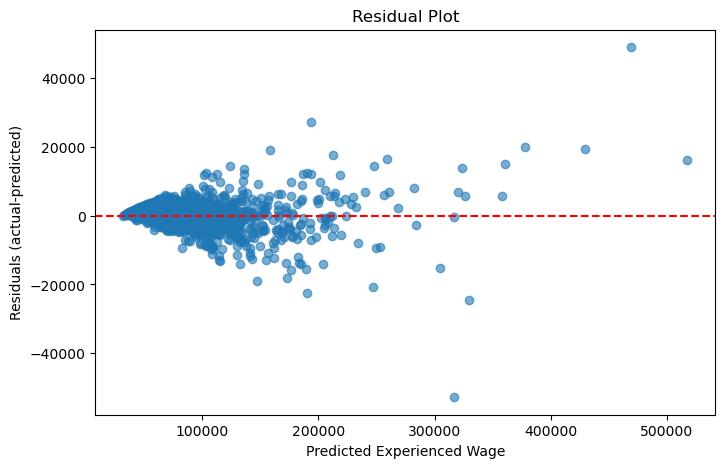

In [11]:
residuals = Y_test - Y_Pred

plt.figure(figsize=(8,5))
plt.scatter(Y_Pred, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Experienced Wage")
plt.ylabel("Residuals (actual-predicted)")
plt.title("Residual Plot")
plt.show()

This plot shows a cone shape indicating constant variance is violated, let's do a log transformation to try to resolve this.

Let's also check for normality using a histogram of the residuals

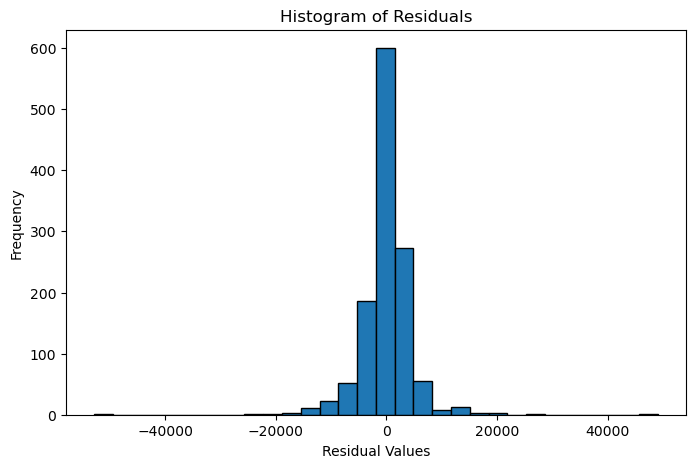

In [12]:
plt.figure(figsize=(8,5))
plt.hist(residuals, bins=30, edgecolor='black')
plt.xlabel("Residual Values")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")
plt.show()

Let's make our transformations
and rerun some of our code previously based off these new transformations

In [13]:
df["log_Mean"] = np.log(df["Mean Wage"])
df["log_Experienced"] = np.log(df["Experienced Wage"])

X2 = df["log_Mean"].values
Y2 = df["log_Experienced"].values

np.random.seed(64)
indices = np.random.permutation(len(df))

split = int(0.8 * len(df))
train_idx = indices[:split]
test_idx = indices[split:]

X2_train, Y2_train = X2[train_idx], Y2[train_idx]
X2_test, Y2_test = X2[test_idx], Y2[test_idx]

beta0_2, beta1_2 = linear_regression_fit(X2_train, Y2_train)

print("Intercept: ", beta0_2)
print("Slope: ", beta1_2)

Y2_Pred_test = linear_regression_predict(X2_test, beta0_2, beta1_2)

print("R^2: ", r_squared(Y2_test, Y2_Pred_test))

Intercept:  -0.7535923207388606
Slope:  1.0794605709865823
R^2:  0.9944381327547741


Now for the plots

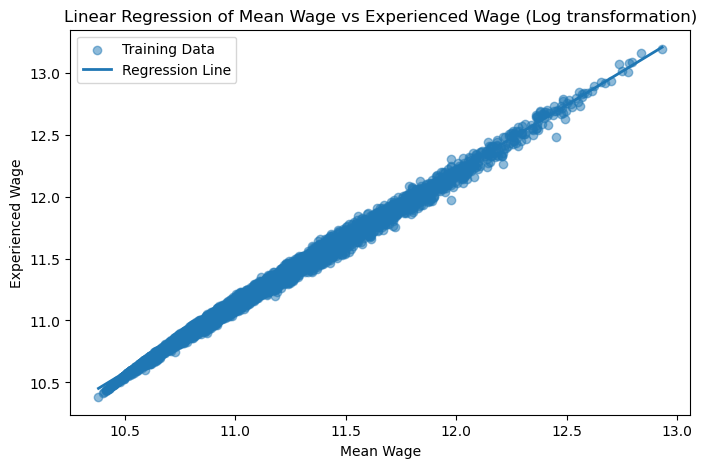

In [14]:
X2_line = np.linspace(min(X2_train), max(X2_train), 100)
Y2_line = beta0_2 + beta1_2 * X2_line

plt.figure(figsize=(8,5))
plt.scatter(X2_train, Y2_train, alpha=0.5, label="Training Data")
plt.plot(X2_line, Y2_line, label="Regression Line", linewidth=2)
plt.xlabel("Mean Wage")
plt.ylabel("Experienced Wage")
plt.title("Linear Regression of Mean Wage vs Experienced Wage (Log transformation)")
plt.legend()
plt.show()

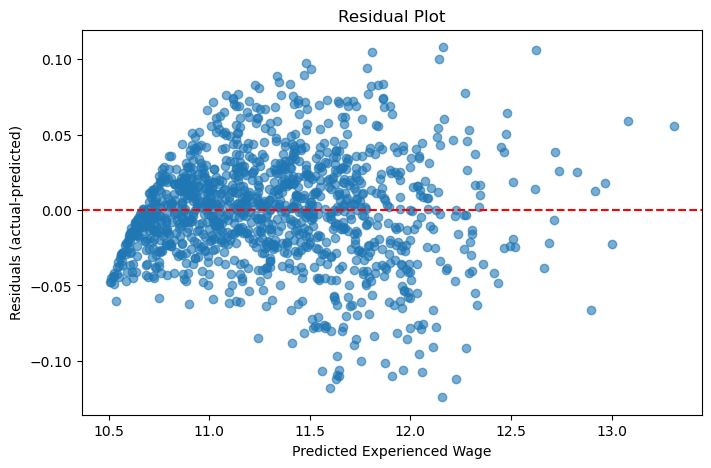

In [15]:
residuals2 = Y2_test - Y2_Pred_test

plt.figure(figsize=(8,5))
plt.scatter(Y2_Pred_test, residuals2, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Experienced Wage")
plt.ylabel("Residuals (actual-predicted)")
plt.title("Residual Plot")
plt.show()

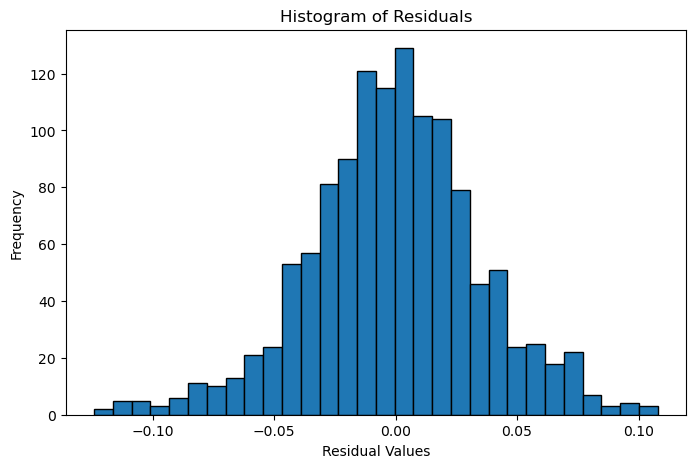

In [16]:
plt.figure(figsize=(8,5))
plt.hist(residuals2, bins=30, edgecolor='black')
plt.xlabel("Residual Values")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")
plt.show()

Back transformation for our model

In [17]:
def predict_correct_scale(x_mean_wage):
    log_pred = beta0_2 + beta1_2 * np.log(x_mean_wage)
    return np.exp(log_pred)

Y_pred_final = predict_correct_scale(X_test)
print(r_squared(Y_test, Y_pred_final))

0.9927206987605679


We already had an incredibly high r-squared prior to the transformations, however; the transformations were necessary to prove constant variance requirement was met for the linear regression analysis. 
This also intended to improve our model. While the improvement itself is minimal this is due to the base model already being incredibly accurate.

Now let's compare to some base models, first a KNN regressor

In [18]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

X_train_skl = X2_train.reshape(-1, 1)
X_test_skl  = X2_test.reshape(-1, 1)

knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(X_train_skl, Y2_train)
knn_pred = knn.predict(X_test_skl)
knn_r2 = r2_score(Y2_test, knn_pred)

print(knn_r2)

0.9932267821284775


Now Decision Tree Regressor

In [19]:
tree = DecisionTreeRegressor(random_state=64)
tree.fit(X_train_skl, Y2_train)
tree_pred = tree.predict(X_test_skl)
tree_r2 = r2_score(Y2_test, tree_pred)

print(tree_r2)

0.9902363473328313


Finally, Random Forest Regressor

In [21]:
forest = RandomForestRegressor(
    n_estimators=200,
    random_state=64
)
forest.fit(X_train_skl, Y2_train)
forest_pred = forest.predict(X_test_skl)
forest_r2 = r2_score(Y2_test, forest_pred)

print(forest_r2)

0.9925885341025519


In [53]:
import statsmodels.api as sm
import numpy as np

X_sm = sm.add_constant(X2)
model = sm.OLS(Y2, X_sm).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.994
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                 1.116e+06
Date:                Sat, 22 Nov 2025   Prob (F-statistic):               0.00
Time:                        19:21:02   Log-Likelihood:                 11987.
No. Observations:                6182   AIC:                        -2.397e+04
Df Residuals:                    6180   BIC:                        -2.396e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.7547      0.011    -66.006      0.0

In [57]:
from sklearn.metrics import mean_squared_error
import numpy as np

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_lin = rmse(Y2_test, Y2_Pred_test)
rmse_knn = rmse(Y2_test, knn_pred)
rmse_dt  = rmse(Y2_test, tree_pred)
rmse_rf  = rmse(Y2_test, forest_pred)

print("RMSE - Linear Regression:", rmse_lin,
     "R2 - Linear Regression:", r_squared(Y_test, Y_pred_final))
print("RMSE - KNN:", rmse_knn,
     "R2 - KNN:", knn_r2)
print("RMSE - Decision Tree:", rmse_dt,
     "R2 - Decision Tree:", tree_r2)
print("RMSE - Random Forest:", rmse_rf,
     "R2 - Random Forest:", forest_r2)

RMSE - Linear Regression: 0.035515734470281876 R2 - Linear Regression: 0.9927206987605679
RMSE - KNN: 0.039192955452745405 R2 - KNN: 0.9932267821284775
RMSE - Decision Tree: 0.04705617819485855 R2 - Decision Tree: 0.9902363473328313
RMSE - Random Forest: 0.04099798841506587 R2 - Random Forest: 0.9925885341025519
